#**Modulo V Imágenes en salud**

Dras. Valeria Rulloni- Carolina Maldonado

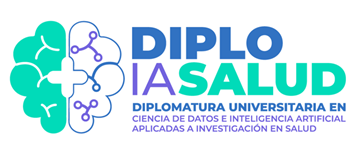

 **Diplomatura en Ciencia de Datos e Inteligencia Artificial
Aplicada a la Investigación en Salud**
Sitio web: https://diploiasalud.sitios.fcm.unc.edu.ar/

# Temario a desarrollar:


1. **Imágenes digitales. Estructura. Tipo de dato: float,
uint8, logical. Imágenes binarias, monocromáticas, a color.**
2. Histograma. Mejora de la imagen:Transformaciones punto a punto, Umbralado y Binarización.
3. Ruido. Filtros. Noción de Vecindad. Filtros lineales. Filtros estadísticos.
4. Práctica integral: Mejora y segmentación. Algoritmos de ML en imágenes (Introducción)


**Recomendación:**
+ Antes que nada **realice una copia de este archivo y trabaje en ella** . Guárdelo en la misma carpeta de preferencia (si está en Colaboratory lo guarda por defecto en la carpeta Colaboratory del drive, se puede reubicar).

# 1 Imágenes: Conceptos Básicos
    





## 1.1  Imágenes binarias y monocromas (arreglos 2D)

Podemos definir una **imagen (monocroma)** como una función o arreglo bidimensional f. En cada coordenada [i,j] tenemos el valor f[i,j]  que es la intensidad de la imagen en dicho punto. Para imágenes en grises (monocroma) o binaria.


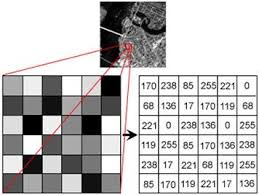

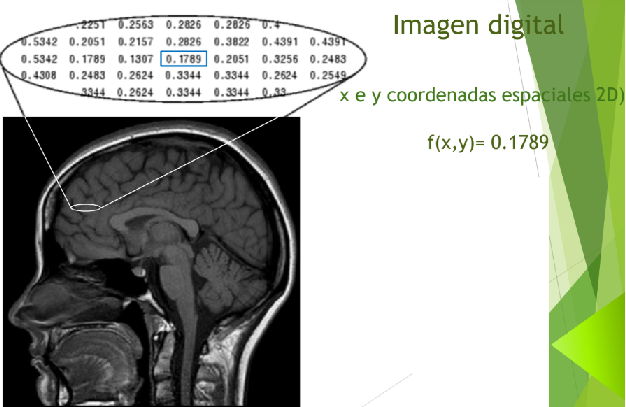


Cada pixel de la imagen está en correspondencia con un elemento [i,j]  del arreglo bidimensional.
Y el valor f([i,j]) asignado para ese lugar del arreglo representa la intensidad del pixel

La intensidad f([i,j]) puede almacenarse como:

- uint8: entero sin signo de 8 bits, su valor pertenece al conjunto {0,1,2,... ,255}.

- uint16: entero sin signo de 16 bits su valor pertenece al conjunto {0,1,...,65535}

- float: número real (no toooodos pero una buena cantidad, negativos y positivos)

- bool, la intensidad toma solo dos valores (en general: los valores 0 o 1.) Imagen binaria.

Al graficar esos datos, lo usual es que
       
* mín valor corresponde al negro   
* máx valor corresponde al blanco.

Salvo que le indiquemos un valor minimo para negro y máximo para blanco. Por ejemplo:
* vmin=0, vmax=1 en float ó
* vmin=0, vmax=255 en uint8



La indexación de la imagen en Python sigue la convención habitual de matrices, **primero fila y luego columna, pero comenzando en 0 c/u.**

En el caso de imágenes en grises (monocroma), al pixel le corresponde un número que es el valor de intensidad I[i,j], en la coordenada/lugar [i,j]

La coordenada [0,0] corresponde a la esquina superior izquierda de la imagen.
La coordenada [m-1, n-1] a la esquina inferior derecha.

* **Tamaño de la imagen**: Si es monocroma (en grises) o binaria es el número de filas por el número de columnas,  m×n. Cada punto corresponde a un píxel.


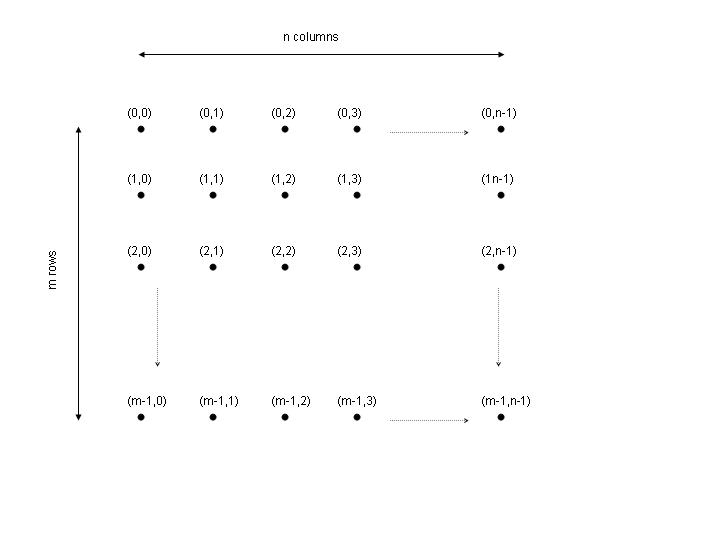

## 1.2 Imágenes RGB:arreglos 3D.

En el caso de imágenes a color vamos a considerar el formato RGB (3 canales).

* Si es a color, cada pixel tiene 3 valores de intensidad, uno por cada canal: R, G y B (red, green, blue).
* Si es imagen satelital hay tantos valores como bandas o canales tenga la imagen (depende de la cantidad de sensores del satélite).

Para RGB, el tamaño del array será MxNx3. almacenando así en cada posición [i,j] la intensidad de cada canal R, G y B. La intensidad del rojo (R) estará en el lugar [i,j,0], la intensidad del verde (G) estará en [i,j,1] y, por último la del azul (B) estará en [i,j,2].

* **Tamaño de la imagen**:  
* a color RGB, es MxNx3.
* salelital: MxNxk donde k es la cantidad de bandas (espectrales).

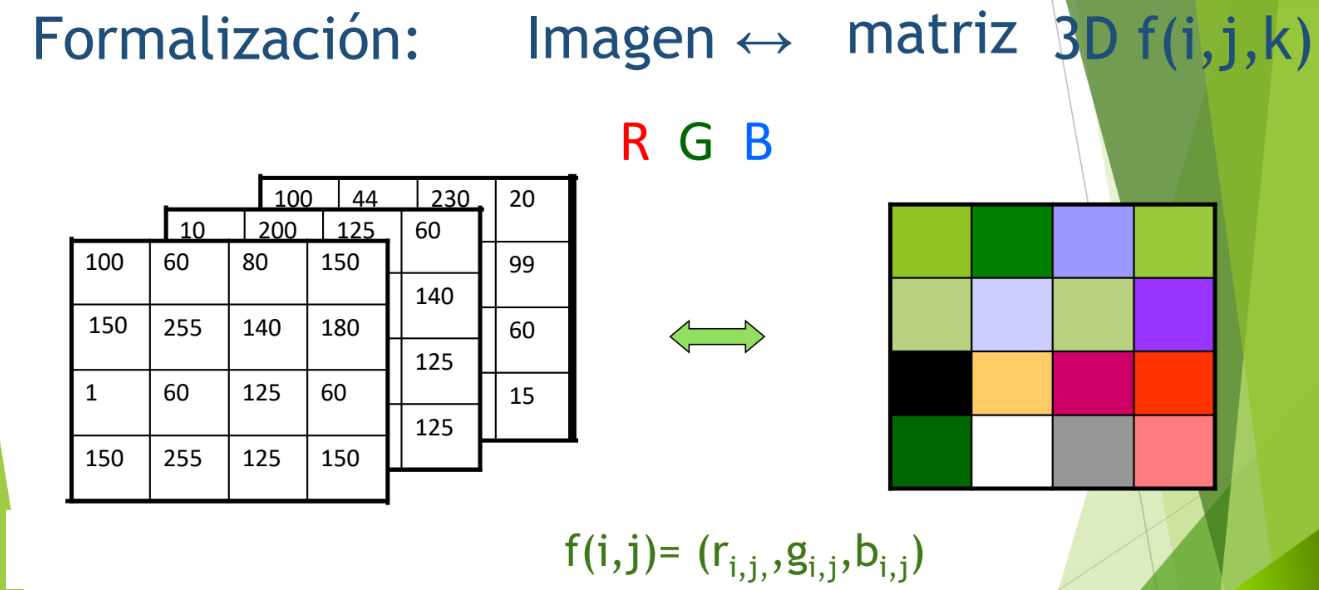

# 2 Imágenes. Práctica
Archivos necesarios:
- 'lunar.jpg',
- 'ortopanto_perfil.jpeg'

En Colab subimos el archivo asi:

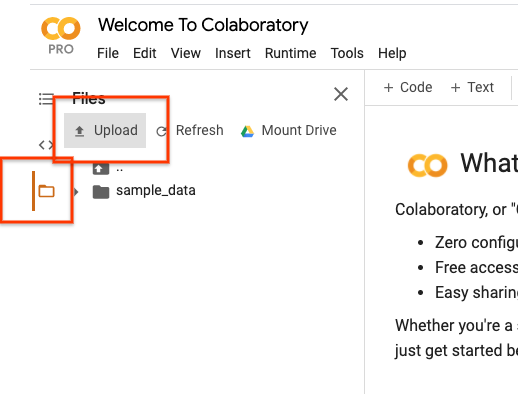

## 2.1 Imagen monocroma

Abrimos una imagen monocroma, la guardamos como un "arreglo" y la visualizamos.

Arreglo=una estructura espacialmente ordenada para guardar datos, con tamaño prefijado. (que no cambia)

Librerias que usamos:

*   Numpy para generar los arreglos o matrices.
* OpenCV para leer imagenes y cargarlas como arreglos. https://docs.opencv.org/3.4/index.html
https://numpy.org/
*  Matplotlib para mostrarlas o visualizarlas. https://matplotlib.org/



  


**Observación**

Algunas librerías como Opencv ya vienen pre-instaladas en Google Colab. Si no será necesario instalarla algunas librerías.

 **!pip install nombre_libreria**






In [ ]:
import cv2
print(cv2.__version__)

4.13.0


In [ ]:
import cv2
img = cv2.imread('ortopanto_perfil.jpeg') #leemos la imagen


In [ ]:
print(f"Tipo de matriz: {type(img)}")
print(f"Tipo de dato del píxel: {img.dtype}")
print(f"Tamaño de la imagen: {img.shape}")


Tipo de matriz: <class 'numpy.ndarray'>
Tipo de dato del píxel: uint8
Tamaño de la imagen: (411, 1088, 3)


Visualizamos la imegen con la libreria matplotlib

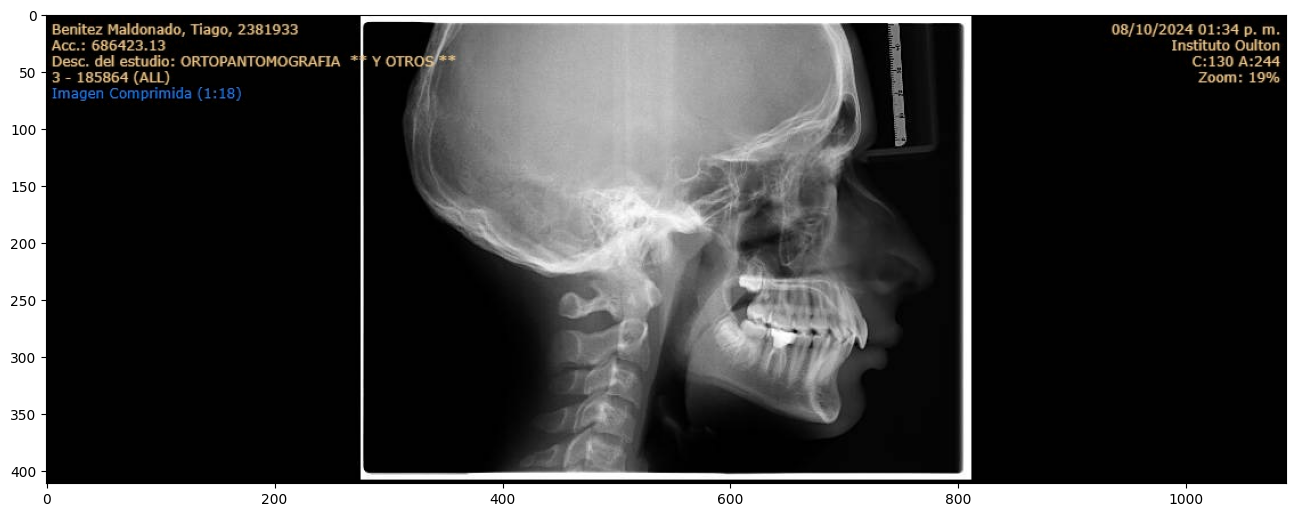

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(16,12))
plt.imshow(img)

**Vamos a inspecionar la imagen en algunas posiciones**

In [ ]:
#accedo al un solo lugar [i,j]
i=200
j=520
print(f"{img[i,j]} Es la intensidad de la imagen en el lugar:[{i},{j}] ")

[197 197 197] Es la intensidad de la imagen en el lugar:[200,520] 


In [ ]:
#accedo a un rango de posiciones  [i,j]
i=200
rango_i=5

j=520
rango_j=3
print(f"{img[i:i+rango_i,j:j+rango_j]} ")
print(f"Son todas las intensidades desde la fila {i} hasta {i+rango_i-1} y columna {j}  hasta {j+rango_j-1} ")


[[[197 197 197]
  [208 208 208]
  [212 212 212]]

 [[206 206 206]
  [212 212 212]
  [209 209 209]]

 [[210 210 210]
  [209 209 209]
  [200 200 200]]

 [[203 203 203]
  [200 200 200]
  [189 189 189]]

 [[196 196 196]
  [193 193 193]
  [183 183 183]]] 
Son todas las intensidades desde la fila 200 hasta 204 y columna 520  hasta 522 


Ejercicio 1: Mirando la grilla de filas y columnas de la imagen, cambiar las posiciones y los rangos y hacer "print". Relacionar con lo que ve de la imagen.

Observacion importante. ES UN DATO RGB (3 canales).

En la zona de la imagen médica tiene intensidades repetidas. En general las imágenes médicas vienen con 3 canales pero info repetida.

Puedo quedarme con 1 solo canal y trabajar con el dato **monocromo** o 2D.

In [ ]:
img_mono = cv2.imread('ortopanto_perfil.jpeg',0) #con el 0 al final cv2.imread carga un dato monocromo
print(f"Tipo de matriz: {type(img_mono)}")
print(f"Tipo de dato del píxel: {img_mono.dtype}")
print(f"Tamaño de la imagen: {img_mono.shape}")
print(f"{img[i,j]} es la intensidad de la imagen en el lugar:[{i},{j}] ")

Tipo de matriz: <class 'numpy.ndarray'>
Tipo de dato del píxel: uint8
Tamaño de la imagen: (411, 1088)
[197 197 197] es la intensidad de la imagen en el lugar:[200,520] 


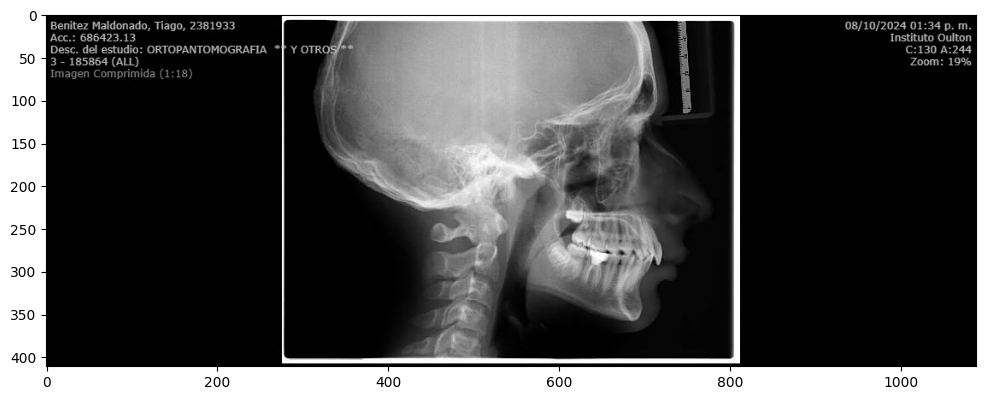

In [ ]:
plt.figure(figsize=(12,8))
plt.imshow(img_mono,cmap='gray')

Hacemos un recorte de la imagen para quedarnos con la imagen médica y eliminar datos personales y fecha. Nos ayudamos con la barra que indica filas y columnas.

In [ ]:
#elegimos la columna donde queremos empezar y el rango que qieremos abarcar
col=300
range=500

im_recorte=img_mono[:, col:col+range]# los dos puntitos indican todas las filas

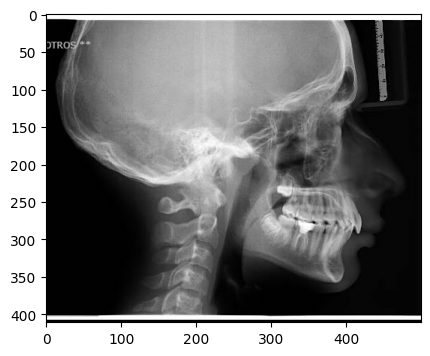

In [ ]:
#visualizamos el recorte
plt.figure(figsize=(8,4)) #puedo cambiar el tamaño de la figura
plt.imshow(im_recorte,cmap='gray')

Ejercicio 2: Mirando la grilla de filas y columnas de la imagen realizar un recorte de filas y columnas de modo de elegir la zona de los dientes.Visualizar

 ## 2.2  **Imagen RGB**

In [ ]:
#leemos la imagen lunar y la cargamos como arreglo 3D
img2 = cv2.imread('lunar.jpg') #leemos la imagen


In [ ]:

#miramos el tipo de dato que tiene esta imagen
print(f"Tipo de matriz: {type(img2)}")
print(f"Tipo de dato del píxel: {img2.dtype}")
print(f"Tamaño de la imagen: {img2.shape}")


Tipo de matriz: <class 'numpy.ndarray'>
Tipo de dato del píxel: uint8
Tamaño de la imagen: (304, 459, 3)


**PRECAUCION CON OPEN CV.**

Carga la imagen directamente a matriz pero en BGR, es decir con los canales cambiados.

**"El dato"** es BGR y no RGB

Si quiero visualizarla con otra libreria fuera de OpenCV OJO


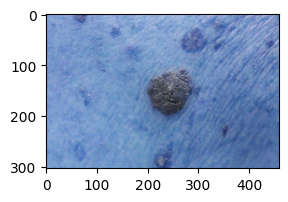

In [ ]:

plt.figure(figsize=(4,2))
plt.imshow(img2)

In [ ]:
#Si quiero trabajar con el dato RGB, lo convierto asi:
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

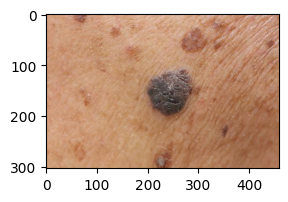

In [ ]:
plt.figure(figsize=(4,2))
plt.imshow(img2_rgb)

Ejercicio 3: ayudándose con la grilla elija una posición que este adentro del lunar mas grande y otra afuera. Observe las intesidades.

Ejercicio 4: ayudándose con la grilla realice un recorte de filas y columnas que contenga al lunar mas grande.

## 2.3  Imágenés DICOM

A esta librería **SI** hay que instalarla

In [ ]:
!pip install pydicom #

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 30.1 MB/s eta 0:00:00


In [ ]:
# Ahora elegimos un archivo Dicom gentileza de:
# authors : Guillaume Lemaitre <g.lemaitre58@gmail.com>
# license : MIT

import matplotlib.pyplot as plt
import pydicom
from pydicom import dcmread
from pydicom.data import get_testdata_file #aqui accedemos a una base de datos y elegimos 1 imagen

fpath = get_testdata_file('CT_small.dcm') # elegimos 1 imagen de es base de datos
ds = dcmread(fpath) #leemos la imagen



In [ ]:
#observamos el tipo de dato
print(type(ds))

<class 'pydicom.dataset.FileDataset'>


In [ ]:
print(ds) #toda la metadata del archivo

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 192
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.6.1.4.1.5962.1.1.1.1.1.20040119072730.12322
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.3.6.1.4.1.5962.2
(0002,0013) Implementation Version Name         SH: 'DCTOOL100'
(0002,0016) Source Application Entity Title     AE: 'CLUNIE1'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'AXIAL']
(0008,0012) Instance Creation Date              DA: '20040119'
(0008,0013) Instance Creation Time              TM: '072731'
(0008,0014) Instance Creator UID                UI: 1.3.6.1.4.

In [ ]:
# Elegimos alguna de toda esa información y la nombramos

print(f"Patient ID.......: {ds.PatientID}")
print(f"Modality.........: {ds.Modality}")
print(f"Study Date.......: {ds.StudyDate}")
print(f"Image size.......: {ds.Rows} x {ds.Columns}")
print(f"Pixel Spacing....: {ds.PixelSpacing}")

Patient ID.......: 1CT1
Modality.........: CT
Study Date.......: 20040119
Image size.......: 128 x 128
Pixel Spacing....: [0.661468, 0.661468]


In [ ]:
#pasamos el archivo a array
imagen_array = ds.pixel_array

# Verificamos las propiedades del array
print(f"Tipo de datos: {type(imagen_array)}")
print(f"Dimensiones de la imagen: {imagen_array.shape}")
print(f"Tipo de valor de los píxeles: {imagen_array.dtype}")

Tipo de datos: <class 'numpy.ndarray'>
Dimensiones de la imagen: (128, 128)
Tipo de valor de los píxeles: int16


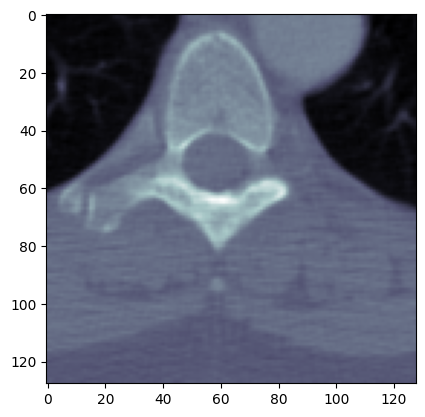

In [ ]:
#ploteamos la imagen
import matplotlib.pyplot as plt
plt.imshow(imagen_array, cmap=plt.cm.bone)
plt.show()